# California Housing: Six-Cluster Grouping System

This project uses unsupervised learning to group California census block groups
by **latitude, longitude, and median income**. It then turns the K-means cluster
assignments into pseudo-labels and tests whether a supervised classifier can
reproduce those labels for unseen rows.

The workflow splits the data before fitting preprocessing or models. K-means is
fit only on training rows; test clusters are assigned with `predict`.

In [1]:
from pathlib import Path
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
if ROOT.name == "src":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from app import FEATURES, N_CLUSTERS, load_housing, split_data

sns.set_theme(style="whitegrid")
print("Features:", FEATURES)
print("Required clusters:", N_CLUSTERS)

Features: ['Latitude', 'Longitude', 'MedInc']
Required clusters: 6


## 1. Load and understand the data

The source is the 4Geeks copy of the California Housing dataset derived from the
1990 census. The unit of observation is a census block group. Only the three
assignment features are used. Repeated values across these selected features
are retained because they can belong to distinct original block groups.

In [2]:
housing = load_housing()
quality = {
    "rows": len(housing),
    "columns": housing.columns.tolist(),
    "missing_values": housing.isna().sum().to_dict(),
    "repeated_selected_feature_rows": int(housing.duplicated().sum()),
}
quality

{'rows': 20640,
 'columns': ['Latitude', 'Longitude', 'MedInc'],
 'missing_values': {'Latitude': 0, 'Longitude': 0, 'MedInc': 0},
 'repeated_selected_feature_rows': 5}

In [3]:
housing.describe().T

,count,mean,std,min,25%,50%,75%,max
Latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
Longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
MedInc,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001


Latitude/longitude are geographic coordinates while `MedInc` is measured in
tens of thousands of dollars. K-means is distance-based, so leaving the units
unscaled would let whichever feature has the largest numerical variance dominate.
The saved pipeline therefore learns a `StandardScaler` on training data before
K-means.

In [4]:
train_raw, test_raw = split_data(housing)
{"train_rows": len(train_raw), "test_rows": len(test_raw), "test_share": len(test_raw) / len(housing)}

{'train_rows': 16512, 'test_rows': 4128, 'test_share': 0.2}

## 2. Required six-cluster K-means model

The model uses `n_clusters=6`, 20 centroid initializations, and a fixed random
seed. Multiple initializations reduce the risk of accepting a poor local optimum.
The cluster number itself has no natural ordering: cluster 5 is not “greater”
than cluster 2.

In [5]:
train = pd.read_csv(ROOT / "data/processed/housing_train_clustered.csv")
test = pd.read_csv(ROOT / "data/processed/housing_test_clustered.csv")
profiles = pd.read_csv(ROOT / "data/processed/cluster_profiles.csv")
metrics = json.loads((ROOT / "data/processed/metrics.json").read_text())

{
    "inertia": metrics["kmeans_inertia"],
    "sampled_silhouette": metrics["train_silhouette"],
    "train_cluster_counts": metrics["cluster_counts_train"],
}

{'inertia': 8069.139639436689,
 'sampled_silhouette': 0.4012278329743399,
 'train_cluster_counts': {'0': 453,
  '1': 5189,
  '2': 2244,
  '3': 3379,
  '4': 1321,
  '5': 3926}}

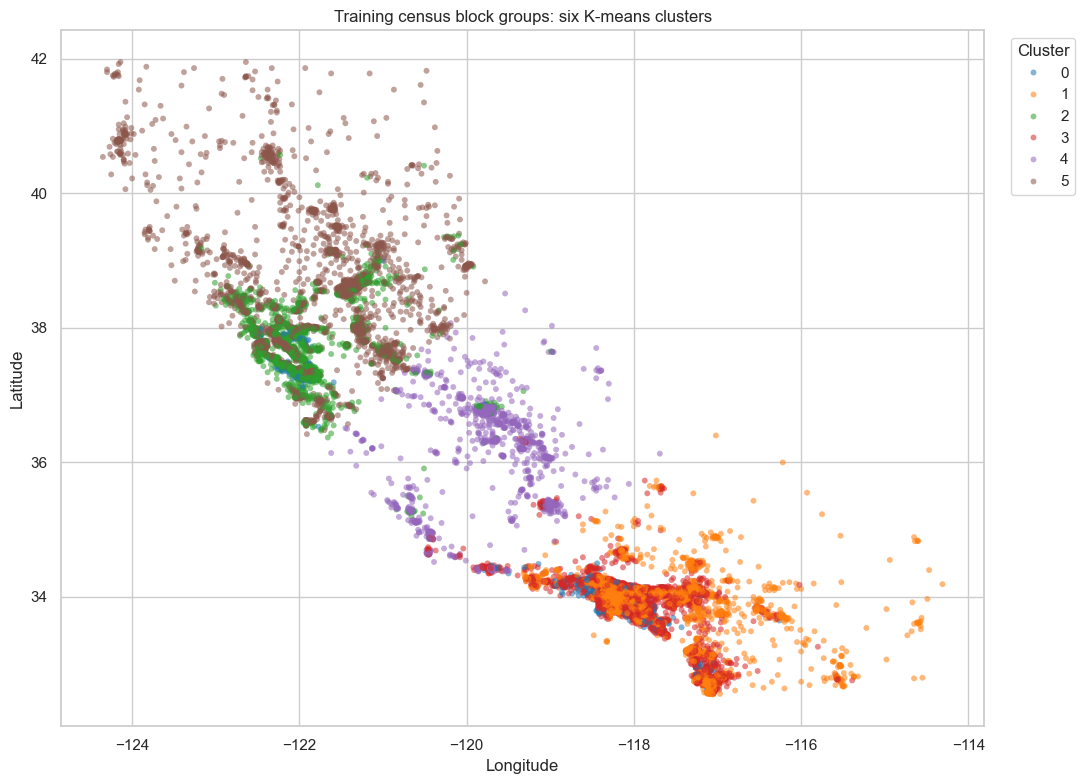

In [6]:
fig, ax = plt.subplots(figsize=(11, 8))
sns.scatterplot(
    data=train,
    x="Longitude",
    y="Latitude",
    hue="cluster",
    palette="tab10",
    alpha=0.55,
    s=18,
    linewidth=0,
    ax=ax,
)
ax.set_title("Training census block groups: six K-means clusters")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [7]:
profiles.round({"Latitude": 3, "Longitude": 3, "MedInc": 2})

,cluster,Latitude,Longitude,MedInc
0,0,34.895,-119.229,10.43
1,1,33.817,-117.816,2.78
2,2,37.701,-121.939,5.52
3,3,33.868,-118.024,5.31
4,4,36.082,-119.728,2.63
5,5,38.347,-121.901,2.83


### What the clusters show

- Geography creates clear northern and southern groupings, especially around
  the large coastal population centers.
- Median income further separates nearby areas: clusters can share a region but
  have very different income centroids.
- Cluster 0 is a small, very-high-income segment (`MedInc` above 10), while the
  largest groups have lower or middle income centroids.
- A silhouette near 0.40 indicates meaningful but overlapping structure—which
  is realistic for geography and income rather than perfectly separated blobs.

## 3. Predict cluster membership for the test set

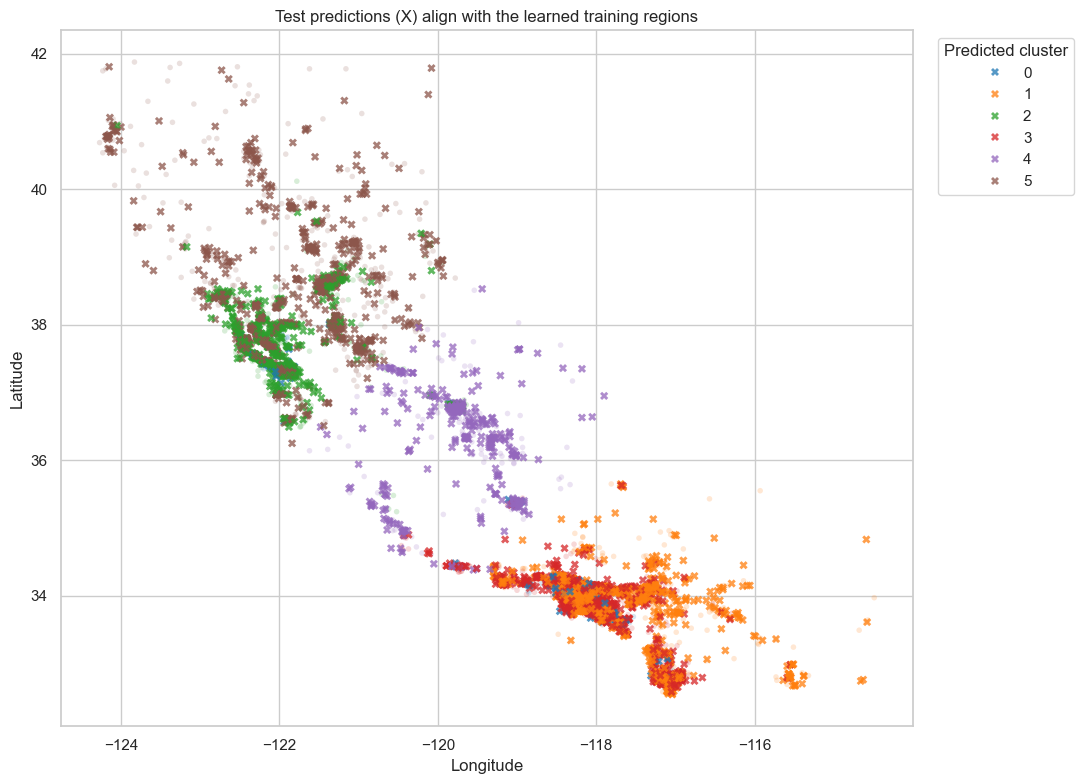

In [8]:
fig, ax = plt.subplots(figsize=(11, 8))
sampled_train = train.sample(4_000, random_state=42)
sns.scatterplot(
    data=sampled_train, x="Longitude", y="Latitude", hue="cluster",
    palette="tab10", alpha=0.18, s=16, linewidth=0, legend=False, ax=ax
)
sns.scatterplot(
    data=test, x="Longitude", y="Latitude", hue="cluster",
    palette="tab10", marker="X", s=35, alpha=0.75, linewidth=0,
    ax=ax
)
ax.set_title("Test predictions (X) align with the learned training regions")
ax.legend(title="Predicted cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

The test points follow the same geographic/income regions as the training
clusters. This is expected because test membership is assigned by proximity to
the six centroids learned from training data—not by refitting on the test set.

## 4. Supervised learning from generated labels

K-means provides pseudo-labels. To choose a supervised model rather than guess,
logistic regression and random forest are compared with five-fold cross-validation
on **training rows only**. Macro F1 is the selection metric because the six
clusters are not equally large and every cluster should matter.

In [9]:
comparison = pd.DataFrame(metrics["classifier_comparison"]).T
comparison.sort_values("cv_macro_f1_mean", ascending=False)

,cv_accuracy_mean,cv_accuracy_std,cv_macro_f1_mean,cv_macro_f1_std
random_forest,0.994004,0.001696,0.990606,0.003392
logistic_regression,0.990492,0.002196,0.984286,0.003395


Selected model: random_forest
Held-out accuracy: 99.4913%
Held-out macro F1: 0.9933


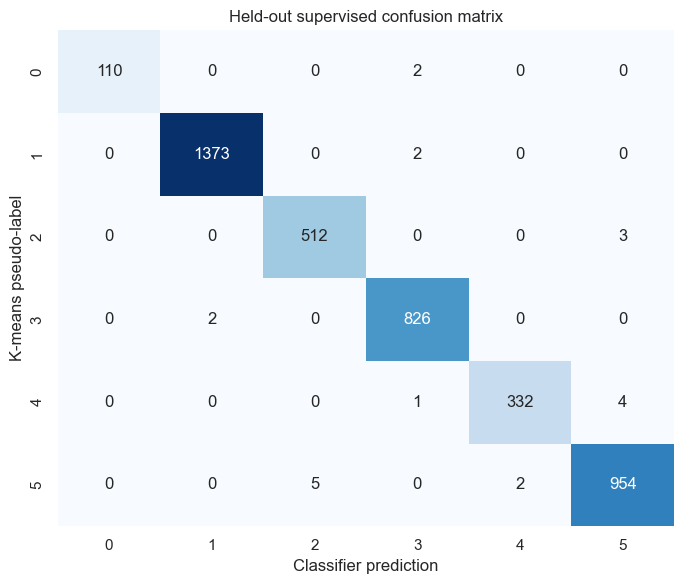

In [10]:
print("Selected model:", metrics["selected_classifier"])
print(f"Held-out accuracy: {metrics['test_accuracy']:.4%}")
print(f"Held-out macro F1: {metrics['test_macro_f1']:.4f}")

matrix = np.asarray(metrics["test_confusion_matrix"])
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set(xlabel="Classifier prediction", ylabel="K-means pseudo-label",
       title="Held-out supervised confusion matrix")
plt.tight_layout()
plt.show()

Random forest has the stronger and more stable cross-validated macro F1 and is
therefore selected. On 4,128 held-out rows it reproduces the K-means assignments
with **99.49% accuracy** and **0.9933 macro F1**. This does not prove the clusters
are ground truth; it proves the learned K-means partition can be approximated
reliably by the supervised model.

## 5. Saved-model demonstration

In [11]:
clusterer = joblib.load(ROOT / "models/kmeans_pipeline.joblib")
classifier = joblib.load(ROOT / "models/cluster_classifier.joblib")
examples = test[FEATURES].head(5)
pd.DataFrame({
    **{feature: examples[feature].values for feature in FEATURES},
    "kmeans_cluster": clusterer.predict(examples),
    "classifier_cluster": classifier.predict(examples),
})

,Latitude,Longitude,MedInc,kmeans_cluster,classifier_cluster
0,36.06,-119.01,1.6812,4,4
1,35.14,-119.46,2.5313,4,4
2,37.80,-122.44,3.4801,5,5
3,34.28,-118.72,5.7376,3,3
4,36.62,-121.93,3.7250,5,5


## 6. Conclusions and limitations

- Scaling is essential because distance across latitude, longitude, and income
  must be comparable.
- Fitting the scaler and K-means only on training data prevents test leakage.
- The six groups capture a combination of geographic region and income band.
- The supervised model accurately imitates K-means, enabling cheap assignment
  when the clustering pipeline is not the serving choice.
- Cluster labels are generated, not human truth. K-means assumes roughly convex
  distance-based groups, is sensitive to scaling and outliers, and does not prove
  social or economic causality. A real deployment should examine stability over
  seeds/time and review whether these segments support a legitimate decision.